# 01 – BBBP Data Audit

The BBBP dataset (MoleculeNet) labels small molecules as blood-brain barrier **penetrating (1)** or
**non-penetrating (0)**. Before any modelling, this notebook checks the data quality and the structure of the
chemical space, because both decide how trustworthy later results can be.

**Questions**
1. How balanced are the labels?
2. Are all SMILES valid, and are there duplicates or duplicates with conflicting labels?
3. Do simple physicochemical properties already separate the classes (and how well)?
4. How are molecules distributed over Murcko scaffolds? This determines how a scaffold split will look.

**Output:** a cleaned table `data/processed/bbbp_clean.csv` with a log of every removal.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.*")   # invalid SMILES are counted below instead of flooding the output
plt.style.use("seaborn-v0_8")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

csv_path = DATA_RAW / "BBBP.csv"
assert csv_path.exists(), f"{csv_path} not found. Run the download step first."

## 2. Load the raw data

In [2]:
raw = pd.read_csv(csv_path)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
assert {"name", "p_np", "smiles"} <= set(raw.columns), "Unexpected column names"

df = raw.rename(columns={"p_np": "label"})[["name", "smiles", "label"]].copy()
df["row_id"] = raw.index   # original row position, kept for the removal log

print("\nMissing values per column:")
print(df.isna().sum())
df.head()

Shape: (2050, 4)
Columns: ['num', 'name', 'p_np', 'smiles']

Missing values per column:
name      0
smiles    0
label     0
row_id    0
dtype: int64


,name,smiles,label,row_id
0,Propanolol,[Cl].CC(C)NCC(O)COc1cccc2ccccc12,1,0
1,Terbutylchlorambucil,C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl,1,1
2,40730,c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...,1,2
3,24,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C,1,3
4,cloxacillin,Cc1onc(c2ccccc2Cl)c1C(=O)N[C@H]3[C@H]4SC(C)(C)...,1,4


## 3. Label balance

       count  share
label              
0        483  0.236
1       1567  0.764


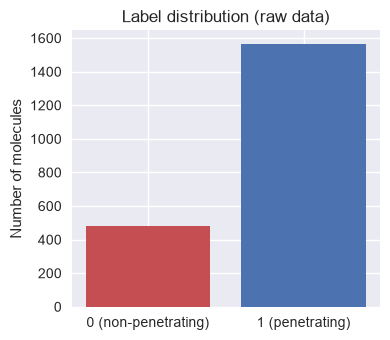

In [3]:
label_counts = df["label"].value_counts().sort_index()
label_share = df["label"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"count": label_counts, "share": label_share.round(3)}))

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["0 (non-penetrating)", "1 (penetrating)"], label_counts.values, color=["#c44e52", "#4c72b0"])
ax.set_ylabel("Number of molecules")
ax.set_title("Label distribution (raw data)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_label_distribution.png", dpi=150)
plt.show()

A clear imbalance means that accuracy alone is misleading, exactly as in the ECG project. Later evaluation
should report ROC-AUC, PR-AUC and per-class recall, and compare against a majority-class baseline.

## 4. SMILES validity

RDKit returns `None` for SMILES it cannot parse. These molecules cannot be featurised and must be removed, and
their number is part of the data description.

In [4]:
df["mol"] = df["smiles"].apply(lambda s: Chem.MolFromSmiles(s) if isinstance(s, str) else None)
invalid = df[df["mol"].isna()]

print(f"Invalid SMILES: {len(invalid)} of {len(df)}")
invalid[["row_id", "name", "smiles", "label"]]

Invalid SMILES: 11 of 2050


,row_id,name,smiles,label
59,59,15,O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3,1
61,61,22767,c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC,1
391,391,ICI17148,Cc1nc(sc1)\[NH]=C(\N)N,1
614,614,5-6,s1cc(CSCCN\C(NC)=[NH]\C#N)nc1\[NH]=C(\N)N,1
642,642,12,c1c(c(ncc1)CSCCN\C(=[NH]\C#N)NCC)Br,0
645,645,16,n1c(csc1\[NH]=C(\N)N)c1ccccc1,1
646,646,17,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N,0
647,647,18,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)NC(C)=O,0
648,648,19,n1c(csc1\[NH]=C(\N)N)c1cccc(c1)N\C(NC)=[NH]\C#N,0
649,649,2,s1cc(nc1\[NH]=C(\N)N)C,1


## 5. Canonical SMILES, duplicates and label conflicts

Different SMILES strings can describe the same molecule, so duplicates are searched on **canonical SMILES**.

- **Consistent duplicates** (same molecule, same label): redundant, keep one.
- **Conflicting duplicates** (same molecule, different labels): label noise. The true label is unknown, so these
  molecules are removed entirely instead of keeping an arbitrary one.

Molecules with several fragments (a `.` in the SMILES, typically salts) are only counted here. Whether to strip them
is decided in the next notebook, since it can change which molecules count as duplicates.

In [5]:
valid = df[df["mol"].notna()].copy()
valid["canonical_smiles"] = valid["mol"].apply(Chem.MolToSmiles)

grouped = valid.groupby("canonical_smiles")
group_size = grouped.size()
group_labels = grouped["label"].nunique()

conflicting_smiles = group_labels[group_labels > 1].index
consistent_dup_smiles = group_size[(group_size > 1) & (group_labels == 1)].index

print("Valid molecules:                         ", len(valid))
print("Unique canonical SMILES:                 ", group_size.shape[0])
print("Groups with consistent duplicates:       ", len(consistent_dup_smiles))
print("Groups with conflicting labels:          ", len(conflicting_smiles))
print("Molecules with several fragments ('.'):  ", int(valid["canonical_smiles"].str.contains(".", regex=False).sum()))
print("Names that occur more than once:         ", int((valid["name"].value_counts() > 1).sum()))

conflicts = valid[valid["canonical_smiles"].isin(conflicting_smiles)].sort_values("canonical_smiles")
conflicts[["row_id", "name", "label", "canonical_smiles"]]

Valid molecules:                          2039
Unique canonical SMILES:                  1975
Groups with consistent duplicates:        50
Groups with conflicting labels:           10
Molecules with several fragments ('.'):   105
Names that occur more than once:          21


,row_id,name,label,canonical_smiles
100,100,acetylsalicylate,0,CC(=O)Oc1ccccc1C(=O)O
1007,1007,aspirin,1,CC(=O)Oc1ccccc1C(=O)O
1334,1334,loratadine,1,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
569,569,loratadine,0,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1
16,16,BRL53080,1,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccc...
550,550,loperamide,0,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccc...
126,126,atropine,0,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
1697,1697,atropine(hyoscyamine),1,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
174,174,Trimetrexate,0,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC
1641,1641,trimetrexate,1,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC


## 6. Cleaning and removal log

In [6]:
no_conflict = valid[~valid["canonical_smiles"].isin(conflicting_smiles)]
clean = no_conflict.drop_duplicates("canonical_smiles", keep="first").copy()

log = pd.DataFrame({
    "step": ["raw rows", "invalid SMILES removed", "rows in conflicting groups removed",
             "consistent duplicate rows removed", "clean molecules"],
    "count": [len(df), len(invalid), len(valid) - len(no_conflict),
              len(no_conflict) - len(clean), len(clean)],
})
print(log.to_string(index=False))

assert clean["canonical_smiles"].is_unique
assert log["count"].iloc[0] - log["count"].iloc[1:4].sum() == log["count"].iloc[4]

clean_out = clean[["row_id", "name", "canonical_smiles", "label"]].rename(columns={"canonical_smiles": "smiles"})
clean_out.to_csv(DATA_PROCESSED / "bbbp_clean.csv", index=False)
log.to_csv(PROJECT_ROOT / "results" / "01_cleaning_log.csv", index=False)
print("\nSaved:", DATA_PROCESSED / "bbbp_clean.csv")
print("Label share after cleaning:")
print(clean["label"].value_counts(normalize=True).sort_index().round(3))

                              step  count
                          raw rows   2050
            invalid SMILES removed     11
rows in conflicting groups removed     20
 consistent duplicate rows removed     54
                   clean molecules   1965

Saved: /Users/niclasrosenberger/projects/bbbp-permeability-prediction/data/processed/bbbp_clean.csv
Label share after cleaning:
label
0    0.237
1    0.763
Name: proportion, dtype: float64


## 7. Physicochemical properties by class

Rules of thumb in the literature link barrier penetration with properties such as a low polar surface area and few
hydrogen-bond donors. This section checks how strongly that holds in this dataset. The single-descriptor ROC-AUC
shows how well one number alone separates the classes: **above 0.5 means that higher values go with penetrating
molecules, below 0.5 that higher values go with non-penetrating molecules.** It is a descriptive check, not a model.

In [7]:
def describe(mol):
    return {
        "mol_wt": Descriptors.MolWt(mol),
        "logp": Descriptors.MolLogP(mol),
        "tpsa": rdMolDescriptors.CalcTPSA(mol),
        "hbd": rdMolDescriptors.CalcNumHBD(mol),
        "hba": rdMolDescriptors.CalcNumHBA(mol),
        "rot_bonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "heavy_atoms": mol.GetNumHeavyAtoms(),
    }

props = pd.DataFrame([describe(m) for m in clean["mol"]], index=clean.index)
clean = pd.concat([clean, props], axis=1)
prop_cols = list(props.columns)

summary = clean.groupby("label")[prop_cols].median().T
summary.columns = ["median (label 0)", "median (label 1)"]
summary["single-feature AUC"] = [roc_auc_score(clean["label"], clean[col]) for col in prop_cols]
summary.round(3)

,median (label 0),median (label 1),single-feature AUC
mol_wt,409.317,308.566,0.291
logp,1.228,2.795,0.703
tpsa,111.100,47.890,0.167
hbd,3.000,1.000,0.189
hba,6.000,3.000,0.218
rot_bonds,5.000,3.000,0.347
heavy_atoms,28.000,22.000,0.309


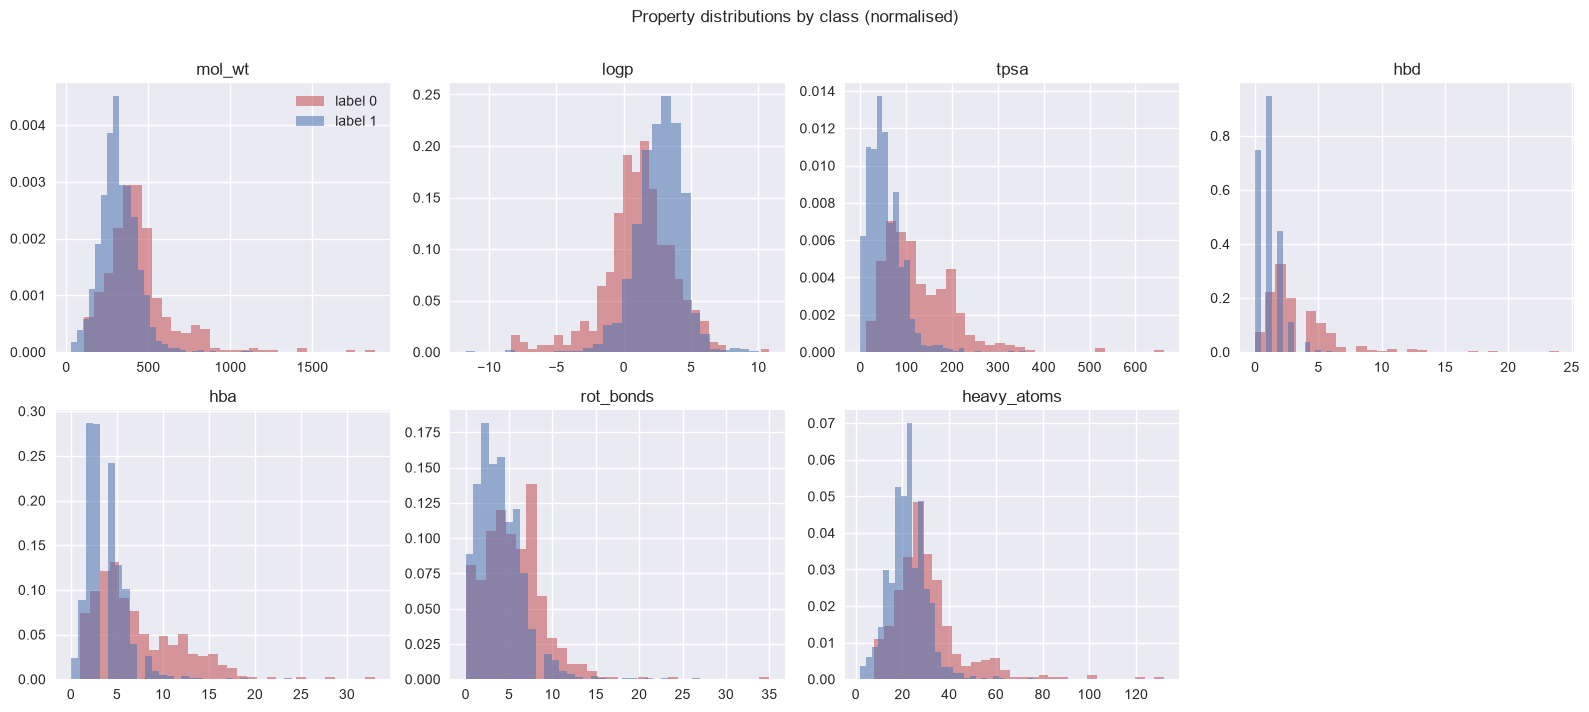

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), prop_cols):
    for label, color in [(0, "#c44e52"), (1, "#4c72b0")]:
        ax.hist(clean.loc[clean["label"] == label, col], bins=30, alpha=0.55, density=True,
                color=color, label=f"label {label}")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
axes.ravel()[0].legend()
plt.suptitle("Property distributions by class (normalised)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_property_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Strong single-descriptor AUCs mean that a simple baseline on these properties will already perform well. A later
fingerprint or graph model must be compared against such a descriptor baseline to show it adds something.

## 8. Scaffold structure

A Murcko scaffold is the ring system of a molecule including the linkers between rings. Molecules with an identical
scaffold are close relatives, so a random split puts near-copies into training and test sets. A **scaffold split**
assigns whole scaffold groups to one side. The group sizes below show how such a split will behave: a few large
groups and many singletons mean that the split is dominated by the large groups, similar to the large records in the
ECG data.

In [9]:
clean["scaffold"] = clean["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))

sizes = clean.groupby("scaffold").size().sort_values(ascending=False)
n_acyclic = int((clean["scaffold"] == "").sum())
singleton_scaffolds = sizes[sizes == 1].index

print("Molecules:                              ", len(clean))
print("Unique scaffolds:                       ", len(sizes))
print("Molecules without ring system (empty):  ", n_acyclic, f"({n_acyclic / len(clean):.1%})")
print("Scaffolds with a single molecule:       ", len(singleton_scaffolds),
      f"({len(singleton_scaffolds) / len(sizes):.1%} of scaffolds)")
print("Molecules in the 10 largest scaffolds:  ", int(sizes.head(10).sum()),
      f"({sizes.head(10).sum() / len(clean):.1%})")

top = (clean.groupby("scaffold")
       .agg(n=("label", "size"), positive_rate=("label", "mean"))
       .sort_values("n", ascending=False).head(10))
top.index = [s if s else "(no ring system)" for s in top.index]
top.round(2)

Molecules:                               1965
Unique scaffolds:                        1020
Molecules without ring system (empty):   95 (4.8%)
Scaffolds with a single molecule:        777 (76.2% of scaffolds)
Molecules in the 10 largest scaffolds:   439 (22.3%)


,n,positive_rate
c1ccccc1,128,0.73
(no ring system),95,0.93
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21,74,0.96
O=C1CN=C(c2ccccc2)c2ccccc2N1,26,1.00
O=C1C=C2CCC3C4CCCC4CCC3C2CC1,24,0.67
c1ccc2c(c1)Nc1ccccc1S2,22,1.00
c1ccc(Cc2ccccc2)cc1,20,0.95
O=C1CC(=O)NC(=O)N1,18,1.00
O=C(Cc1ccccc1)N1CCNCC1CN1CCCC1,17,0.29
O=C1C=CC2C(=C1)CCC1C2CCC2C1CC1OCOC12,15,1.00


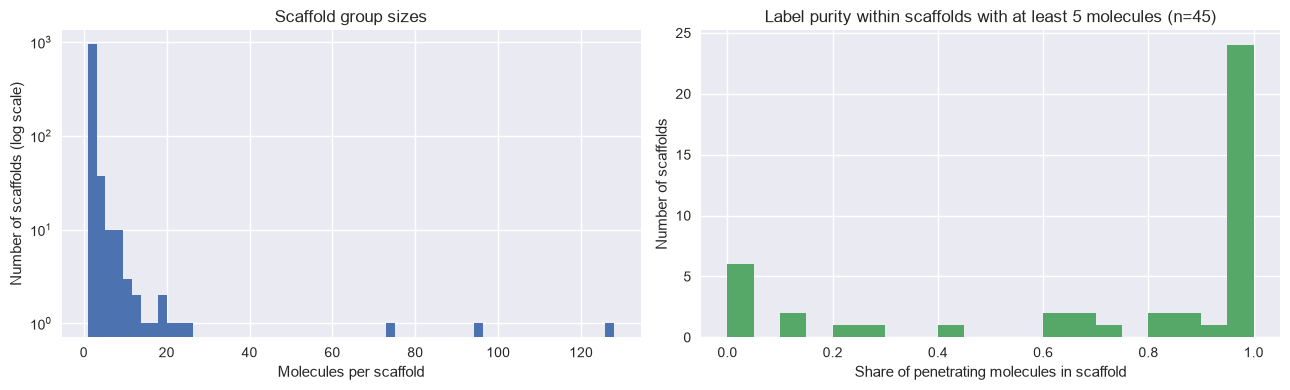

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(sizes.values, bins=np.arange(1, sizes.max() + 2) - 0.5 if sizes.max() < 60 else 60, color="#4c72b0")
axes[0].set_yscale("log")
axes[0].set_xlabel("Molecules per scaffold")
axes[0].set_ylabel("Number of scaffolds (log scale)")
axes[0].set_title("Scaffold group sizes")

multi = clean.groupby("scaffold").agg(n=("label", "size"), rate=("label", "mean"))
multi = multi[(multi["n"] >= 5) & (multi.index != "")]
axes[1].hist(multi["rate"], bins=20, color="#55a868")
axes[1].set_xlabel("Share of penetrating molecules in scaffold")
axes[1].set_ylabel("Number of scaffolds")
axes[1].set_title(f"Label purity within scaffolds with at least 5 molecules (n={len(multi)})")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_scaffold_structure.png", dpi=150)
plt.show()

If many larger scaffolds are almost pure (all penetrating or all non-penetrating), the scaffold identity itself
carries label information. A scaffold split removes that shortcut, which is why scaffold-split scores are usually lower
than random-split scores.

## Summary and next steps

Fill in after running, keeping each statement tied to the tables above:

1. **Labels:** class balance after cleaning and what it means for the metrics.
2. **Data quality:** number of invalid SMILES, consistent duplicates and conflicting groups (from the removal log).
3. **Descriptors:** which properties separate the classes best (single-feature AUC) and what this implies for the
   baseline.
4. **Scaffolds:** number of scaffolds, share of singletons and size of the largest groups.

**Limitations**
- Salt and multi-fragment molecules are counted, not yet standardised.
- Stereochemistry is kept as given in the SMILES.
- BBBP is a relatively small dataset with labels from heterogeneous sources, so its label noise cannot be fully
  assessed from the data alone.

**Next:** `02_splits_and_baselines.ipynb` – standardise molecules, build random and scaffold splits, and train
descriptor and fingerprint baselines with bootstrap uncertainty.